# Bombs: card strength in draft decks

How much of a drafter's win rate comes from the strength of the cards in their deck, and how much do decks differ in
card strength? This notebook rates every card two ways, by GIH WR and by IWD, for every set we have, and then scores each Premier
Draft deck by the average rating of its cards. Every table and plot is shown for both ratings.

* **GIH WR** is the win rate of games in which the card was in the opening hand or drawn (17Lands' headline card stat).
* **Normalized GIH WR** is the card's GIH WR **minus the set's average game win rate**, in percentage points (pp). 17Lands
  users win ~55% of games and the exact baseline differs by set and event, so raw GIH WR isn't comparable across
  sets.
* **IWD** (improvement when drawn) is GIH WR minus **GNS WR**, the win rate of games where the card was in the deck but
  never seen. It's already a difference, so it needs no set baseline. It compares games with the same deck, so it isolates
  the card from the deck it tends to be in, but it's biased by game length: long games see more cards, and games that are
  lost fast tend to be ones where little was drawn.
* **Shrinkage.** Per-card estimates are noisy, and the extremes are biased outward. So every card is shrunk toward the
  average for its rarity (empirical Bayes, normal–normal) before use.

Sections:
1. Per-card GIH WR and IWD for every set and event
2. Deck strength: the average rating of the cards in each deck, how it relates to win rate and to total games won, and
   how much it varies between drafters
3. Bombs: upper-outlier cards under each rating

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import card_metadata
from openlane.deckstrength import aligned, flag
from openlane.games import game_path

OUT = ROOT / "results" / "bombs"
OUT.mkdir(parents=True, exist_ok=True)
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
EVENTS = ["PremierDraft", "Sealed"]
MIN_GIH = 200          # games with the card in hand; below this a card is dropped
K = 5
METRICS = {"gih": "GIH WR", "iwd": "IWD"}   # key -> label; every analysis runs once per metric

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
EV_COLOR = {"PremierDraft": BLUE, "Sealed": ORANGE}
M_COLOR = {"gih": BLUE, "iwd": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True); pl.Config.set_float_precision(2)

polars.config.Config

## 1. Per-card GIH WR and IWD for every set and event

For each game file, one row per card: games in hand (GIH) and in deck but not seen (GNS), GIH WR, GNS WR, normalized
GIH WR (pp above the set average), IWD (pp), and the shrunk versions of both (`norm_eb`, `iwd_eb`).

The shrinkage is done within each rarity. Each card's observed value is $x_i$ with sampling variance $s_i^2$: $p(1-p)/n_i$ for
GIH WR, and $p(1-p)/n_{\mathrm{GIH}} + q(1-q)/n_{\mathrm{GNS}}$ for IWD. Within a rarity the
true values are assumed $\sim N(\mu_r, \tau_r^2)$, with $\mu_r$ the precision-weighted mean and
$\tau_r^2 = \max(\mathrm{Var}(x) - \overline{s^2}, 0.25\,\mathrm{pp}^2)$. The posterior mean is
$\mu_r + \frac{\tau_r^2}{\tau_r^2 + s_i^2}(x_i - \mu_r)$. Rarity matters here: mythics average several pp above commons, so
a common-wide prior would over-shrink the bombs.

Basic lands are dropped, and so are cards with fewer than `MIN_GIH` games in either GIH or GNS, so both ratings cover the
same cards. Results are cached to `results/bombs/`.

In [2]:
BASICS = ["Plains", "Island", "Swamp", "Mountain", "Forest"]


def eb_shrink(x, se2, groups):
    out = np.empty_like(x)
    for g in np.unique(groups):
        m = groups == g
        w = 1 / se2[m]
        mu = (w * x[m]).sum() / w.sum()
        tau2 = max(x[m].var() - se2[m].mean(), 0.25)
        out[m] = mu + tau2 / (tau2 + se2[m]) * (x[m] - mu)
    return out


RATING = {"gih": "norm_eb", "iwd": "iwd_eb"}   # metric -> shrunk rating column


def rate_cards(g, s, names):
    # per-card ratings on the games in g, in pp: norm = GIH WR above g's average win rate, iwd = GIH WR - GNS WR
    won = flag(g["won"])
    seen = (aligned(g, "opening_hand_", names) + aligned(g, "drawn_", names)) > 0
    unseen = (aligned(g, "deck_", names) > 0) & ~seen
    base = won.mean()
    meta = card_metadata(names, s)
    df = pl.DataFrame({"name": names, "rarity": meta["rarity"],
                       "n_gih": seen.sum(0).astype(np.int64), "n_gns": unseen.sum(0).astype(np.int64),
                       "w_gih": seen[won].sum(0).astype(np.int64), "w_gns": unseen[won].sum(0).astype(np.int64)})
    df = (df.filter((pl.col("n_gih") >= MIN_GIH) & (pl.col("n_gns") >= MIN_GIH) & (pl.col("rarity") != "basic")
                    & ~pl.col("name").is_in(BASICS))
          .with_columns((pl.col("w_gih") / pl.col("n_gih")).alias("gih_wr"), (pl.col("w_gns") / pl.col("n_gns")).alias("gns_wr"))
          .drop("w_gih", "w_gns"))
    p, q = df["gih_wr"].to_numpy(), df["gns_wr"].to_numpy()
    se2 = p * (1 - p) / df["n_gih"].to_numpy() * 1e4
    se2_gns = q * (1 - q) / df["n_gns"].to_numpy() * 1e4
    x, iwd, rarity = (p - base) * 100, (p - q) * 100, df["rarity"].to_numpy()
    return df.with_columns(pl.lit(float(base) * 100).alias("set_wr"), pl.Series("norm", x),
                           pl.Series("norm_eb", eb_shrink(x, se2, rarity)), pl.Series("iwd", iwd),
                           pl.Series("iwd_eb", eb_shrink(iwd, se2 + se2_gns, rarity)))


def card_table(s, event):
    path = OUT / f"{s}.{event}.cards.parquet"
    if path.exists() and "iwd_eb" in pl.read_parquet_schema(path):
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    df = rate_cards(g, s, names).with_columns(
        pl.lit(s).alias("set"), pl.lit(event).alias("event"), pl.lit(g.height).alias("n_games"),
        pl.lit(str(g["draft_time"].min())[:10]).alias("first_day"))
    df.write_parquet(path)
    return df


cards = pl.concat([card_table(s, e) for s in SETS for e in EVENTS], how="diagonal")
info = (cards.group_by("set", "event").agg(pl.first("n_games"), pl.first("set_wr"), pl.first("first_day"),
                                            pl.len().alias("cards"))
        .pivot(on="event", index="set", values=["n_games", "set_wr", "cards", "first_day"]))
SETS = info.sort("first_day_PremierDraft")["set"].to_list()   # release order
info.sort("first_day_PremierDraft").select(
    "set", pl.col("first_day_PremierDraft").alias("first day"),
    "n_games_PremierDraft", "n_games_Sealed", "set_wr_PremierDraft", "set_wr_Sealed", "cards_PremierDraft", "cards_Sealed")

set,first day,n_games_PremierDraft,n_games_Sealed,set_wr_PremierDraft,set_wr_Sealed,cards_PremierDraft,cards_Sealed
str,str,i32,i32,f64,f64,u32,u32
"""NEO""","""2022-02-10""",630450,58903,55.60,54.33,280,276
"""ONE""","""2023-02-02""",583077,56654,54.75,56.34,260,253
"""MOM""","""2023-04-13""",1246850,61294,54.76,55.40,341,331
"""WOE""","""2023-08-31""",1024028,57618,55.20,56.57,307,275
"""LCI""","""2023-11-09""",823614,54609,55.34,55.62,285,277
"""MKM""","""2024-02-06""",964377,52764,54.98,54.52,303,264
"""OTJ""","""2024-04-16""",1172393,54832,54.14,55.29,368,324
"""BLB""","""2024-07-30""",931230,50658,54.60,55.49,268,256
"""DSK""","""2024-09-24""",1011949,55079,54.48,55.86,275,258


## 2. Deck strength: average rating of the deck's cards

For every Premier Draft game, the deck's **score** is the mean shrunk rating of the cards in its main deck,
weighted by number of copies, once with normalized GIH WR (`score_gih`) and once with IWD (`score_iwd`). Basic lands are
left out, and so are the few cards with fewer than `MIN_GIH` games. `cover` is the share of the deck's nonbasic cards
that have a rating (the same for both, since both ratings cover the same cards).

**Cross-fitting.** If a card's rating were computed from the same games it's scoring, every deck's own result would leak into its
score. So drafts (draft_ids) are split into two random halves, and each half's decks are scored with card ratings
estimated from the other half only.

A drafter can rebuild between games, so the score is per game. For drafter-level numbers, it's averaged over that drafter's games.
Only drafts where every game has `cover` ≥ 0.9 are kept, so a drafter's game count and total wins are complete.
Per-game scores are cached to `results/bombs/{set}.PremierDraft.decks.parquet`.

In [3]:
def deck_scores(s, event="PremierDraft"):
    path = OUT / f"{s}.{event}.decks.parquet"
    if path.exists() and "score_iwd" in pl.read_parquet_schema(path):
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    idx = {n: j for j, n in enumerate(names)}
    nonbasic = ~np.isin(names, BASICS)
    deck = aligned(g, "deck_", names).astype(np.float32)
    half = g["draft_id"].hash(seed=7).to_numpy() % 2
    score, cover = {m: np.full(g.height, np.nan) for m in METRICS}, np.zeros(g.height)
    for h in (0, 1):
        r = rate_cards(g.filter(pl.Series(half != h)), s, names)   # ratings from the other half
        j, m = [idx[n] for n in r["name"]], half == h
        d = deck[m][:, j]
        k = d.sum(1)
        for met, col in RATING.items():
            score[met][m] = d @ r[col].to_numpy() / np.maximum(k, 1)
        cover[m] = k / np.maximum(deck[m][:, nonbasic].sum(1), 1)
    out = pl.DataFrame({"draft_id": g["draft_id"], "won": flag(g["won"]), "cover": cover,
                        **{f"score_{m}": score[m] for m in METRICS}})
    out.write_parquet(path)
    return out


decks = {s: deck_scores(s) for s in SETS}
print(f"cover (share of nonbasic deck cards with a rating): median "
      f"{np.median(np.concatenate([d['cover'].to_numpy() for d in decks.values()])):.3f}")

cover (share of nonbasic deck cards with a rating): median 1.000


### 2a. Score vs win rate

Per set, game-level win rate in bins of deck score, shown as pp above the set average on both axes. The thin lines are
individual sets and the thick line pools all of them. A GIH WR score of +1 means the deck's cards average 1pp above the set's
average GIH WR; an IWD score of +1 means they average 1pp more IWD than the set's average deck. Bins are a quarter of
each metric's SD of deck score wide, so the two panels have the same resolution.

How the two scores relate per game is printed below the plot.

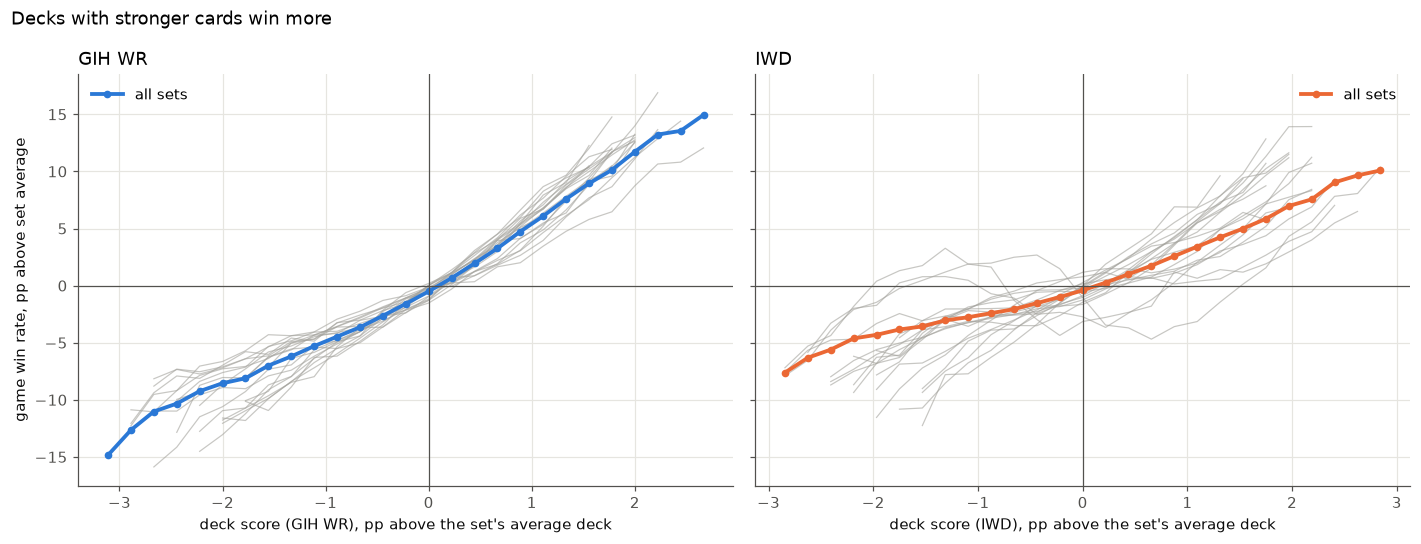

games kept: 14,162,130; per-game correlation of score_gih and score_iwd: median 0.58 (range 0.04 to 0.88)


In [4]:
games = (pl.concat([d.with_columns(pl.lit(s).alias("set")) for s, d in decks.items()])
         .filter((pl.col("cover").min() >= 0.9).over("set", "draft_id")))
games = games.with_columns(((pl.col("won").cast(pl.Float64) - pl.col("won").cast(pl.Float64).mean().over("set")) * 100)
                           .alias("won_c"),
                           *[(pl.col(f"score_{m}") - pl.col(f"score_{m}").mean().over("set")).alias(f"score_c_{m}")
                             for m in METRICS])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (m, label) in zip(axes, METRICS.items()):
    w = 0.25 * games[f"score_c_{m}"].std()
    g = games.with_columns(((pl.col(f"score_c_{m}") / w).round() * w).alias("bin"))
    for s in SETS:
        b = g.filter(pl.col("set") == s).group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 2000).sort("bin")
        ax.plot(b["bin"], b["won_c"], color=GRAY, lw=0.8, alpha=0.6)
    b = g.group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 5000).sort("bin")
    ax.plot(b["bin"], b["won_c"], "o-", color=M_COLOR[m], lw=2.5, ms=4, label="all sets")
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlabel(f"deck score ({label}), pp above the set's average deck")
    ax.set_title(label, loc="left"); ax.legend()
axes[0].set_ylabel("game win rate, pp above set average")
fig.suptitle("Decks with stronger cards win more", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

r_scores = [np.corrcoef(*games.filter(pl.col("set") == s).select("score_gih", "score_iwd").to_numpy().T)[0, 1] for s in SETS]
print(f"games kept: {games.height:,}; per-game correlation of score_gih and score_iwd: median {np.median(r_scores):.2f} "
      f"(range {min(r_scores):.2f} to {max(r_scores):.2f})")

### 2b. Per-set numbers

One table per metric, saved as `deck_score_summary_{gih,iwd}.csv`.

* **sd game**: SD of deck score across games.
* **sd drafter / p10 / p90**: spread of the drafter-average score (drafters with ≥ 3 games), centered on the set mean.
* **r game**: correlation between deck score and the game result (0/1).
* **slope**: pp of game win rate per +1pp of deck score (linear regression on games).
* **sd true WR**: SD of drafters' true win rates. It's the observed SD of per-drafter win rate with the binomial noise
  from their few games subtracted.
* **share explained**: Var(slope × drafter score) / Var(true WR), i.e. how much of the real spread in drafter win
  rates the deck score accounts for.

In [5]:
def per_set_table(m):
    rows = []
    for s in SETS:
        g = games.filter(pl.col("set") == s)
        x, y = g[f"score_{m}"].to_numpy(), g["won"].to_numpy().astype(np.float64)
        slope = np.cov(x, y)[0, 1] / x.var() * 100
        dr = (g.group_by("draft_id").agg(pl.col(f"score_{m}").mean().alias("score"),
                                         pl.col("won").cast(pl.Float64).mean().alias("wr"), pl.len().alias("n"))
              .filter(pl.col("n") >= 3))
        ds, wr, n = dr["score"].to_numpy(), dr["wr"].to_numpy(), dr["n"].to_numpy()
        var_true = wr.var() - np.mean(wr.mean() * (1 - wr.mean()) / n)
        c = ds - ds.mean()
        rows.append({"set": s, "games": g.height, "drafters": dr.height, "sd game": x.std(), "sd drafter": ds.std(),
                     "p10": np.percentile(c, 10), "p90": np.percentile(c, 90), "r game": np.corrcoef(x, y)[0, 1],
                     "slope": slope, "sd true WR": np.sqrt(var_true) * 100,
                     "share explained": (slope * ds.std()) ** 2 / (var_true * 1e4)})
    return pl.DataFrame(rows)


per_set = {}
for m, label in METRICS.items():
    per_set[m] = per_set_table(m)
    per_set[m].write_csv(OUT / f"deck_score_summary_{m}.csv")
    print(f"\n{label}")
    display(per_set[m])
    print("median over sets:", {k: round(float(per_set[m][k].median()), 3) for k in per_set[m].columns[3:]})


GIH WR


set,games,drafters,sd game,sd drafter,p10,p90,r game,slope,sd true WR,share explained
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""NEO""",630450,102334,0.98,0.99,-1.37,1.19,0.09,4.36,9.09,0.22
"""ONE""",583066,96118,1.28,1.29,-1.75,1.67,0.09,3.60,8.73,0.28
"""MOM""",1246850,206175,1.01,1.00,-1.30,1.33,0.09,4.49,8.96,0.25
"""WOE""",1023993,167996,0.84,0.85,-1.13,1.03,0.09,5.38,8.81,0.27
"""LCI""",823611,134913,0.94,0.95,-1.29,1.17,0.11,5.76,8.75,0.39
"""MKM""",964361,158520,0.79,0.80,-1.06,1.01,0.10,6.05,8.55,0.32
"""OTJ""",1172389,194700,0.98,0.98,-1.35,1.21,0.08,4.28,8.61,0.24
"""BLB""",931230,153466,0.84,0.84,-1.15,1.01,0.08,4.72,8.43,0.22
"""DSK""",1011943,166909,0.72,0.72,-0.96,0.90,0.10,6.99,8.51,0.35


median over sets: {'sd game': 0.843, 'sd drafter': 0.853, 'p10': -1.161, 'p90': 1.031, 'r game': 0.093, 'slope': 5.381, 'sd true WR': 8.449, 'share explained': 0.331}



IWD


set,games,drafters,sd game,sd drafter,p10,p90,r game,slope,sd true WR,share explained
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""NEO""",630450,102334,0.91,0.90,-1.27,1.10,0.08,4.17,9.09,0.17
"""ONE""",583066,96118,0.66,0.67,-0.84,0.86,0.06,4.84,8.73,0.14
"""MOM""",1246850,206175,0.85,0.85,-1.15,1.07,0.07,4.06,8.96,0.15
"""WOE""",1023993,167996,0.92,0.92,-1.14,1.28,0.03,1.59,8.81,0.03
"""LCI""",823611,134913,0.82,0.82,-1.01,1.11,0.05,3.23,8.75,0.09
"""MKM""",964361,158520,0.84,0.83,-1.09,1.09,0.05,2.73,8.55,0.07
"""OTJ""",1172389,194700,0.79,0.79,-1.02,1.04,0.03,2.12,8.61,0.04
"""BLB""",931230,153466,1.04,1.04,-1.38,1.32,0.05,2.18,8.43,0.07
"""DSK""",1011943,166909,0.70,0.70,-0.93,0.88,0.06,4.16,8.51,0.12


median over sets: {'sd game': 0.837, 'sd drafter': 0.834, 'p10': -1.091, 'p90': 1.066, 'r game': 0.059, 'slope': 3.448, 'sd true WR': 8.449, 'share explained': 0.128}


### 2b′. Do sets really differ in share explained?

For GIH WR, `share explained` above runs from about 0.20 to 0.47. Is that a real difference between sets, or sampling noise?
The same checks are run for each metric, saved as `share_explained_ci_{gih,iwd}.csv`.

* **Per-set confidence intervals.** Bootstrap over drafts (Poisson weights per `draft_id`, so a draft's games stay together)
  and recompute everything in the `share explained` formula (the game-level slope, the spread of drafter scores, the true WR variance) on each replicate.
* **Do the sets differ at all?** Cochran's Q: $Q = \sum_i (\hat s_i - \bar s)^2 / \mathrm{se}_i^2$ against $\chi^2_{k-1}$, where
  $\bar s$ is the inverse-variance-weighted mean. $I^2 = (Q - (k-1))/Q$ is the share of the between-set spread that isn't
  sampling noise.
* **Does it trend across releases?** An OLS regression of share explained on release order, with a t-test across the 19 sets.
  This treats the sets as the units, so the real between-set differences count as noise, not just the bootstrap SEs.

The card ratings themselves are held fixed. The cross-fitted ratings are estimated from data too, and that noise isn't
in these intervals, so the true intervals are somewhat wider. Noisy ratings also pull the slope down, so a set
with less data (noisier ratings) would show a lower share for that reason alone.

In [6]:
from scipy.stats import chi2, norm as norm_dist, t as t_dist

B = 1000


def draft_sums(m, s):
    # per-draft sums of games, wins and score moments for one set and metric
    d = (games.filter(pl.col("set") == s).with_columns(pl.col("won").cast(pl.Float64), pl.col(f"score_{m}").alias("x"))
         .group_by("draft_id").agg(pl.len().alias("n"), pl.col("x").sum().alias("sx"), pl.col("won").sum().alias("sy"),
                                   (pl.col("x") ** 2).sum().alias("sxx"), (pl.col("x") * pl.col("won")).sum().alias("sxy")))
    return {c: d[c].to_numpy().astype(np.float64) for c in ["n", "sx", "sy", "sxx", "sxy"]}


def share_explained(st, w):
    # st: per-draft sums. w: (replicates, drafts) weights. Same formulas as the table above, as weighted sums.
    G = w @ st["n"]
    mx, my = w @ st["sx"] / G, w @ st["sy"] / G
    slope = (w @ st["sxy"] / G - mx * my) / (w @ st["sxx"] / G - mx ** 2) * 100
    k = st["n"] >= 3
    wd, ds, wr, inv_n = w[:, k], st["sx"][k] / st["n"][k], st["sy"][k] / st["n"][k], 1 / st["n"][k]
    D = wd.sum(1)
    m_ds, m_wr = wd @ ds / D, wd @ wr / D
    var_ds = wd @ ds ** 2 / D - m_ds ** 2
    var_true = wd @ wr ** 2 / D - m_wr ** 2 - m_wr * (1 - m_wr) * (wd @ inv_n) / D
    return slope ** 2 * var_ds / (var_true * 1e4)


share, trend = {}, {}
for m, label in METRICS.items():
    rng = np.random.default_rng(0)
    rows = []
    for s in SETS:
        st = draft_sums(m, s)
        D = len(st["n"])
        boot = np.concatenate([share_explained(st, rng.poisson(1.0, (100, D)).astype(np.float64)) for _ in range(B // 100)])
        rows.append({"set": s, "share explained": share_explained(st, np.ones((1, D)))[0], "se": boot.std(),
                     "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5)})
    share[m] = pl.DataFrame(rows)
    share[m].write_csv(OUT / f"share_explained_ci_{m}.csv")
    print(f"\n{label}")
    with pl.Config(float_precision=3):
        display(share[m])

    est, se, k = share[m]["share explained"].to_numpy(), share[m]["se"].to_numpy(), share[m].height
    w = 1 / se ** 2
    pooled = (w * est).sum() / w.sum()
    Q = (w * (est - pooled) ** 2).sum()
    print(f"heterogeneity: weighted mean {pooled:.3f}, Q = {Q:.0f} on {k - 1} df, p = {chi2.sf(Q, k - 1):.1e}, "
          f"I² = {max(0, (Q - (k - 1)) / Q):.2f}")

    order = np.arange(k, dtype=np.float64)
    b, a = np.polyfit(order, est, 1)
    resid = est - (a + b * order)
    se_b = np.sqrt(resid.var(ddof=2) / ((order - order.mean()) ** 2).sum())
    trend[m] = (a, b)
    print(f"trend over releases: {b * 100:+.2f} pp of share per set (SE {se_b * 100:.2f}), "
          f"t = {b / se_b:.1f}, p = {2 * t_dist.sf(abs(b / se_b), k - 2):.1e}; "
          f"fitted {a:.2f} at {SETS[0]} → {a + b * (k - 1):.2f} at {SETS[-1]}")


GIH WR


set,share explained,se,lo,hi
str,f64,f64,f64,f64
"""NEO""",0.223,0.008,0.209,0.239
"""ONE""",0.281,0.010,0.263,0.300
"""MOM""",0.252,0.006,0.241,0.264
"""WOE""",0.271,0.007,0.257,0.287
"""LCI""",0.390,0.010,0.368,0.409
"""MKM""",0.318,0.009,0.303,0.337
"""OTJ""",0.239,0.006,0.227,0.251
"""BLB""",0.221,0.007,0.208,0.236
"""DSK""",0.354,0.009,0.336,0.372


heterogeneity: weighted mean 0.276, Q = 799 on 18 df, p = 5.4e-158, I² = 0.98
trend over releases: +0.66 pp of share per set (SE 0.27), t = 2.5, p = 2.3e-02; fitted 0.25 at NEO → 0.37 at MSH



IWD


set,share explained,se,lo,hi
str,f64,f64,f64,f64
"""NEO""",0.172,0.007,0.161,0.186
"""ONE""",0.136,0.006,0.124,0.148
"""MOM""",0.149,0.004,0.141,0.157
"""WOE""",0.028,0.002,0.024,0.032
"""LCI""",0.090,0.004,0.083,0.098
"""MKM""",0.071,0.003,0.064,0.077
"""OTJ""",0.037,0.002,0.033,0.041
"""BLB""",0.072,0.003,0.066,0.079
"""DSK""",0.117,0.004,0.108,0.126


heterogeneity: weighted mean 0.051, Q = 4364 on 18 df, p = 0.0e+00, I² = 1.00
trend over releases: +0.34 pp of share per set (SE 0.36), t = 1.0, p = 3.5e-01; fitted 0.09 at NEO → 0.15 at MSH


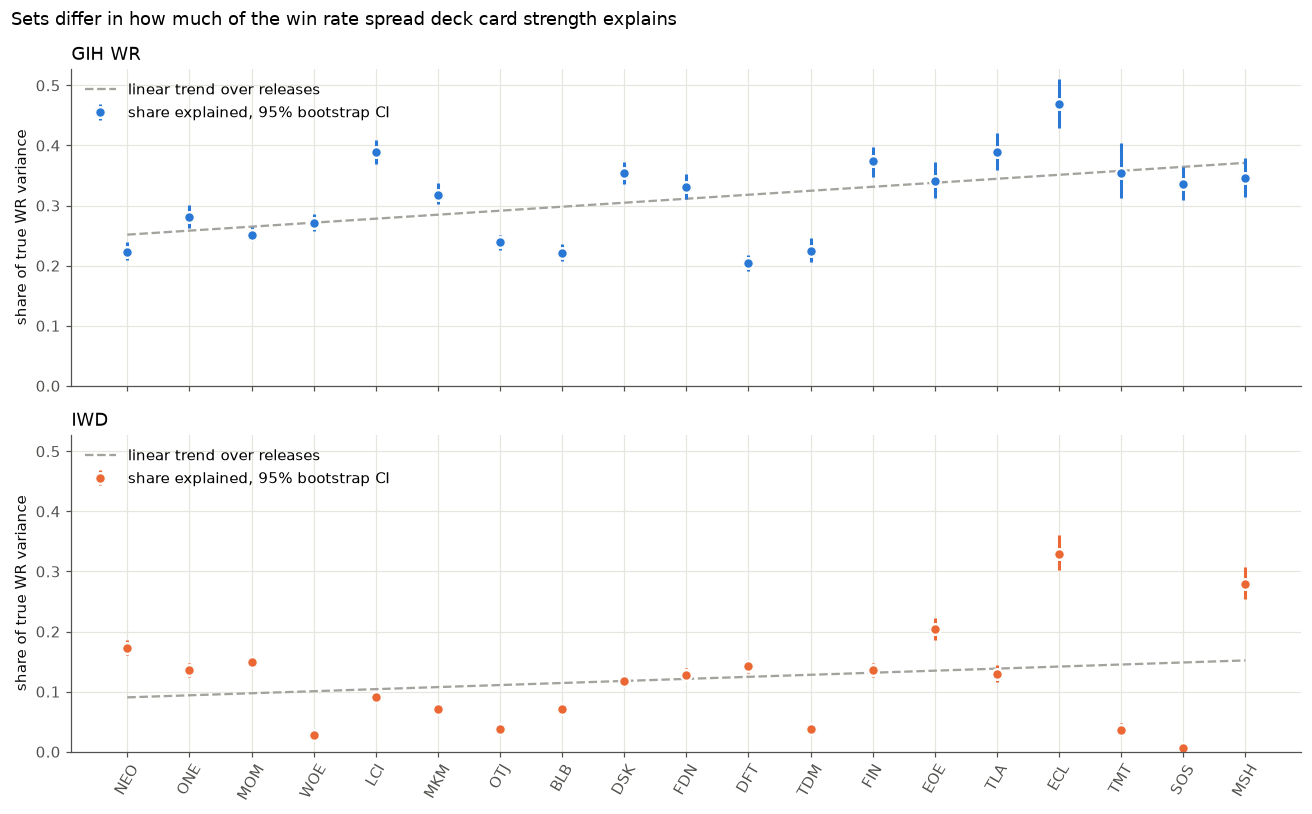

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, sharey=True)
x = np.arange(len(SETS))
for ax, (m, label) in zip(axes, METRICS.items()):
    a, b = trend[m]
    sh = share[m]
    ax.plot(x, a + b * x, color=GRAY, lw=1.5, ls="--", label="linear trend over releases")
    ax.errorbar(x, sh["share explained"], yerr=[sh["share explained"] - sh["lo"], sh["hi"] - sh["share explained"]],
                fmt="o", color=M_COLOR[m], ecolor=M_COLOR[m], elinewidth=2, capsize=0, ms=7, mec=SURFACE, mew=1.5,
                label="share explained, 95% bootstrap CI")
    ax.set_ylim(0, None)
    ax.set_ylabel("share of true WR variance")
    ax.set_title(label, loc="left"); ax.legend(loc="upper left")
axes[1].set_xticks(x, SETS, rotation=60)
fig.suptitle("Sets differ in how much of the win rate spread deck card strength explains", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

### 2b″. Do sets where decks differ more have a higher share explained?

`share explained` is $\mathrm{slope}^2 \cdot \mathrm{sd\,drafter}^2 / \mathrm{sd\,true\,WR}^2$, so a wider spread of drafter
scores would raise it if the slope stayed put. Across the 19 sets it doesn't stay put. The top row plots
each set's `sd drafter` against its `share explained`, and the bottom row plots `sd drafter` against the `slope`.

Taking logs makes the formula a sum, $\log \mathrm{share} = 2\log \mathrm{slope} + 2\log \mathrm{sd\,drafter} - 2\log \mathrm{sd\,true\,WR}$,
so the across-set variance of log share splits exactly into each term's covariance with it. That split is printed below each
metric: the fraction of the between-set differences in share that comes from each term (the three add up to 1, and a negative
fraction means that term works against the differences).

GIH WR: sd drafter vs share explained r = -0.17 (p = 0.496), Spearman -0.16 (p = 0.509); sd drafter vs slope r = -0.82
   share of between-set variance in log share explained: slope +1.00, sd drafter -0.25, sd true WR +0.26
IWD: sd drafter vs share explained r = -0.67 (p = 0.002), Spearman -0.69 (p = 0.001); sd drafter vs slope r = -0.83
   share of between-set variance in log share explained: slope +1.43, sd drafter -0.42, sd true WR -0.01


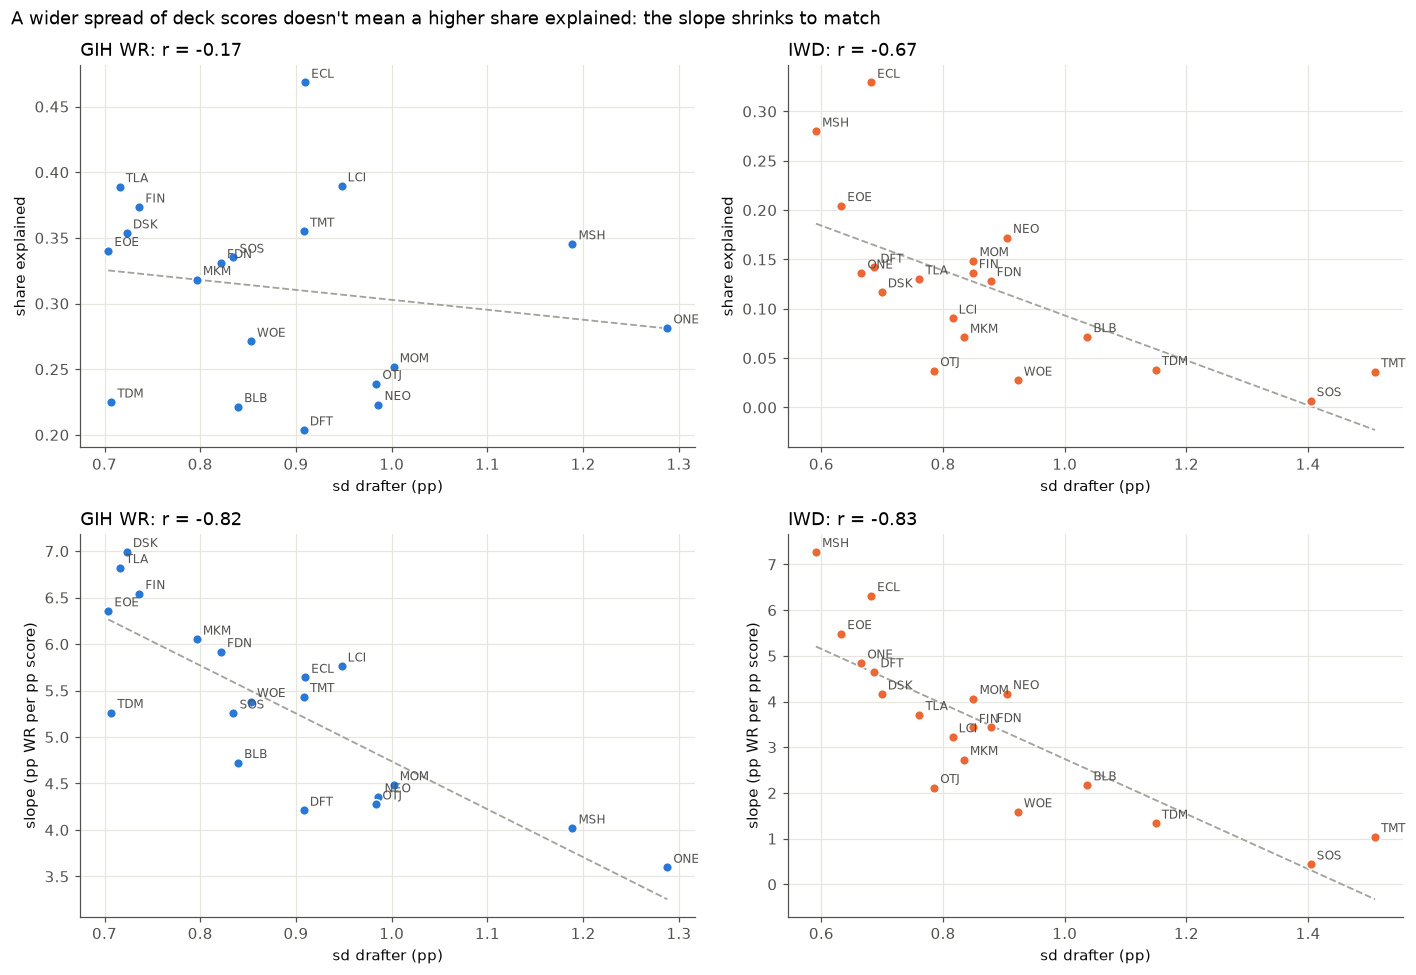

In [ ]:
from scipy.stats import pearsonr, spearmanr

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for j, (m, label) in enumerate(METRICS.items()):
    d = per_set[m]
    sd, sh, sl, st = (d[c].to_numpy() for c in ["sd drafter", "share explained", "slope", "sd true WR"])
    for ax, y, ylab in [(axes[0, j], sh, "share explained"), (axes[1, j], sl, "slope (pp WR per pp score)")]:
        ax.scatter(sd, y, color=M_COLOR[m], s=40, edgecolor=SURFACE, lw=1, zorder=3)
        for s, xi, yi in zip(d["set"], sd, y):
            ax.annotate(s, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=8, color=MUTED)
        b, a = np.polyfit(sd, y, 1)
        xx = np.linspace(sd.min(), sd.max(), 2)
        ax.plot(xx, a + b * xx, color=GRAY, lw=1.2, ls="--")
        ax.set_xlabel("sd drafter (pp)"); ax.set_ylabel(ylab)
        ax.set_title(f"{label}: r = {pearsonr(sd, y)[0]:+.2f}", loc="left")

    L = np.log(sh)
    parts = {"slope": 2 * np.log(sl), "sd drafter": 2 * np.log(sd), "sd true WR": -2 * np.log(st)}
    split = {k: np.cov(L, v)[0, 1] / L.var(ddof=1) for k, v in parts.items()}
    r, p = pearsonr(sd, sh); rho, p_rho = spearmanr(sd, sh)
    print(f"{label}: sd drafter vs share explained r = {r:+.2f} (p = {p:.3f}), Spearman {rho:+.2f} (p = {p_rho:.3f}); "
          f"sd drafter vs slope r = {pearsonr(sd, sl)[0]:+.2f}")
    print("   share of between-set variance in log share explained: "
          + ", ".join(f"{k} {v:+.2f}" for k, v in split.items()))
fig.suptitle("A wider spread of deck scores doesn't mean a higher share explained: the slope shrinks to match",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

### 2c. How much do drafters' decks differ?

The distribution of the drafter-average deck score (pp above the set's average deck) for each set, in release order, for each metric. Boxes
are the 25th to 75th percentile and whiskers the 5th to 95th.

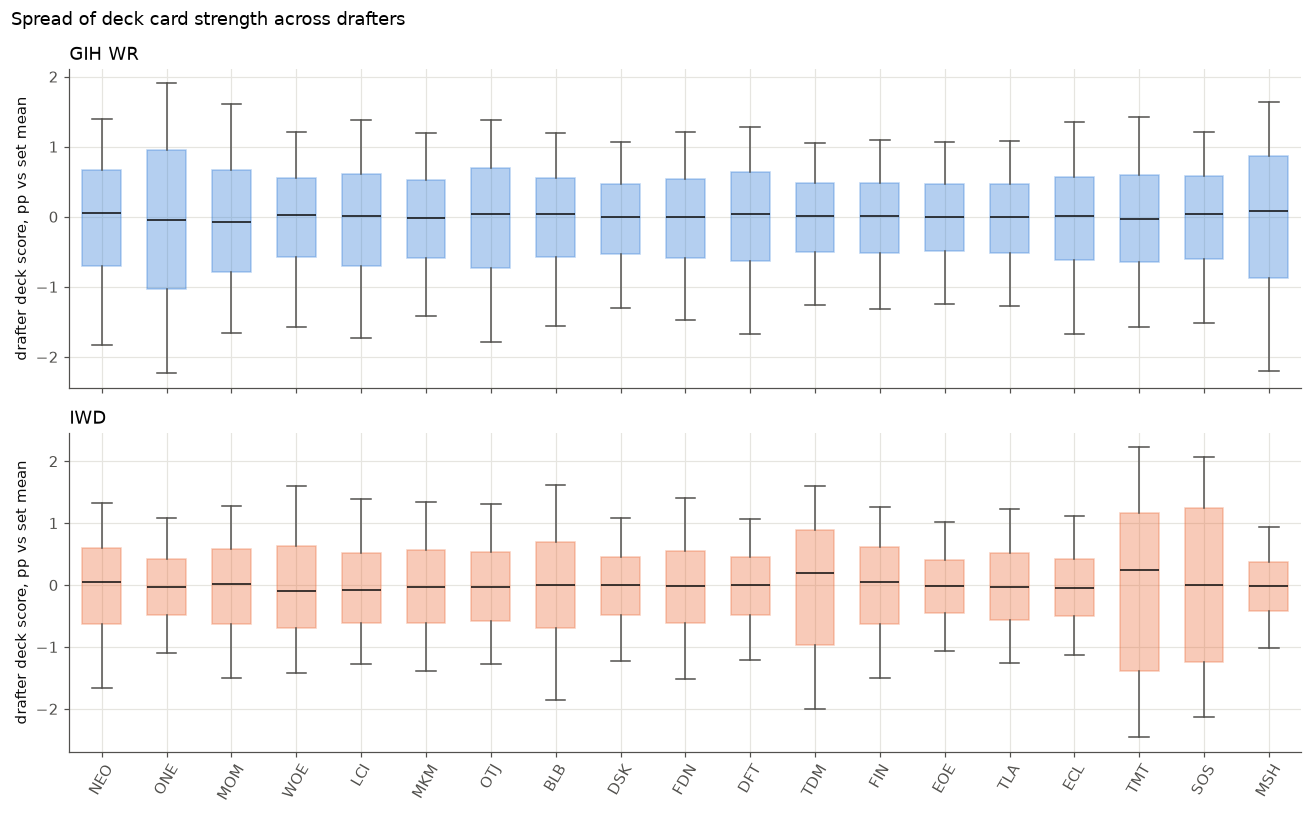

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
for ax, (m, label) in zip(axes, METRICS.items()):
    dist = []
    for s in SETS:
        dr = (games.filter(pl.col("set") == s).group_by("draft_id").agg(pl.col(f"score_c_{m}").mean(), pl.len())
              .filter(pl.col("len") >= 3))
        dist.append(dr[f"score_c_{m}"].to_numpy())
    ax.boxplot(dist, whis=(5, 95), showfliers=False, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=M_COLOR[m], alpha=0.35, edgecolor=M_COLOR[m]), medianprops=dict(color=INK),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    ax.set_ylabel("drafter deck score, pp vs set mean")
    ax.set_title(label, loc="left")
axes[1].set_xticks(range(1, len(SETS) + 1), SETS, rotation=60)
fig.suptitle("Spread of deck card strength across drafters", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

### 2d. Deck score vs total games won: GIH WR or IWD?

For each drafter (draft_id), **total wins** is the number of logged games they won with that draft, and their score is the
average deck score over those games. A Premier Draft run ends at 7 wins or 3 losses, so total wins is the outcome a drafter
actually cares about. It mixes win rate with run length, and it's noisy: one draft is only a handful of games.

* **r wins**: per set, the correlation between drafter score and total wins, for each metric. All drafters are included.
* **IWD − GIH**: the difference between the two correlations. Both are computed on the same drafters, so the difference is
  bootstrapped **paired** (the same Poisson draft weights for both), which is much tighter than comparing two separate CIs.
  `p` is a two-sided normal test of the difference using its bootstrap SE.
* Overall, the per-set differences are combined by inverse-variance weighting, and the number of sets where IWD wins is
  counted (a sign test, which doesn't depend on the SEs).

The plot on the left shows mean total wins by drafter score, with the score in SD units (within each set) so the two
metrics share an axis. The right plot shows each set's r with its 95% CI.

In [9]:
from scipy.stats import binomtest

drafts = (games.group_by("set", "draft_id")
          .agg(pl.len().alias("games"), pl.col("won").cast(pl.Float64).sum().alias("wins"),
               *[pl.col(f"score_{m}").mean() for m in METRICS])
          .with_columns(*[((pl.col(f"score_{m}") - pl.col(f"score_{m}").mean().over("set"))
                           / pl.col(f"score_{m}").std().over("set")).alias(f"z_{m}") for m in METRICS]))


def wcorr(x, y, w):
    # weighted Pearson r of x and y for each row of weights w (replicates, drafts)
    W = w.sum(1)
    mx, my = w @ x / W, w @ y / W
    return (w @ (x * y) / W - mx * my) / np.sqrt((w @ (x * x) / W - mx ** 2) * (w @ (y * y) / W - my ** 2))


rng = np.random.default_rng(1)
rows = []
for s in SETS:
    d = drafts.filter(pl.col("set") == s)
    y = d["wins"].to_numpy()
    xs = {m: d[f"score_{m}"].to_numpy() for m in METRICS}
    boot = {m: [] for m in METRICS}
    for _ in range(B // 100):
        w = rng.poisson(1.0, (100, d.height)).astype(np.float64)
        for m in METRICS:
            boot[m].append(wcorr(xs[m], y, w))
    boot = {m: np.concatenate(v) for m, v in boot.items()}
    one = np.ones((1, d.height))
    r = {m: wcorr(xs[m], y, one)[0] for m in METRICS}
    diff, se_diff = r["iwd"] - r["gih"], (boot["iwd"] - boot["gih"]).std()
    rows.append({"set": s, "drafters": d.height, "mean wins": y.mean(),
                 **{f"r wins {m}": r[m] for m in METRICS},
                 **{f"lo {m}": np.percentile(boot[m], 2.5) for m in METRICS},
                 **{f"hi {m}": np.percentile(boot[m], 97.5) for m in METRICS},
                 "IWD − GIH": diff, "se diff": se_diff, "p": 2 * norm_dist.sf(abs(diff / se_diff))})
wins_r = pl.DataFrame(rows)
wins_r.write_csv(OUT / "wins_correlation.csv")
with pl.Config(float_precision=3):
    display(wins_r.select("set", "drafters", "mean wins", "r wins gih", "r wins iwd", "IWD − GIH", "se diff", "p"))

diff, se = wins_r["IWD − GIH"].to_numpy(), wins_r["se diff"].to_numpy()
w = 1 / se ** 2
pooled, se_pooled = (w * diff).sum() / w.sum(), 1 / np.sqrt(w.sum())
Q = (w * (diff - pooled) ** 2).sum()
wins_iwd = int((diff > 0).sum())
print(f"median r wins: GIH WR {wins_r['r wins gih'].median():.3f}, IWD {wins_r['r wins iwd'].median():.3f}")
print(f"IWD − GIH, inverse-variance pooled: {pooled:+.4f} (SE {se_pooled:.4f}), z = {pooled / se_pooled:.1f}, "
      f"p = {2 * norm_dist.sf(abs(pooled / se_pooled)):.1e}; across-set heterogeneity Q = {Q:.0f} on {len(SETS) - 1} df "
      f"(p = {chi2.sf(Q, len(SETS) - 1):.1e})")
print(f"IWD has the higher r in {wins_iwd} of {len(SETS)} sets (sign test p = {binomtest(wins_iwd, len(SETS)).pvalue:.2g}); "
      f"significant at p < 0.05 in {int(((wins_r['p'] < 0.05) & (wins_r['IWD − GIH'] > 0)).sum())} for IWD, "
      f"{int(((wins_r['p'] < 0.05) & (wins_r['IWD − GIH'] < 0)).sum())} for GIH WR")
pooled_r = {m: np.corrcoef(drafts[f"z_{m}"], drafts["wins"] - drafts["wins"].mean())[0, 1] for m in METRICS}
print("all sets pooled (score standardized within set):", {METRICS[m]: round(v, 3) for m, v in pooled_r.items()})

set,drafters,mean wins,r wins gih,r wins iwd,IWD − GIH,se diff,p
str,i64,f64,f64,f64,f64,f64,f64
"""NEO""",106250,3.299,0.204,0.180,-0.024,0.001,0.000
"""ONE""",99932,3.194,0.218,0.152,-0.066,0.004,0.000
"""MOM""",215027,3.175,0.208,0.160,-0.048,0.002,0.000
"""WOE""",175012,3.230,0.215,0.065,-0.150,0.003,0.000
"""LCI""",140363,3.247,0.260,0.123,-0.137,0.004,0.000
"""MKM""",165246,3.209,0.227,0.107,-0.120,0.003,0.000
"""OTJ""",202231,3.139,0.198,0.078,-0.120,0.003,0.000
"""BLB""",160150,3.175,0.184,0.101,-0.082,0.002,0.000
"""DSK""",173543,3.177,0.238,0.137,-0.100,0.003,0.000


median r wins: GIH WR 0.212, IWD 0.130
IWD − GIH, inverse-variance pooled: -0.0726 (SE 0.0005), z = -132.4, p = 0.0e+00; across-set heterogeneity Q = 5049 on 18 df (p = 0.0e+00)
IWD has the higher r in 0 of 19 sets (sign test p = 3.8e-06); significant at p < 0.05 in 0 for IWD, 19 for GIH WR
all sets pooled (score standardized within set): {'GIH WR': np.float64(0.211), 'IWD': np.float64(0.122)}


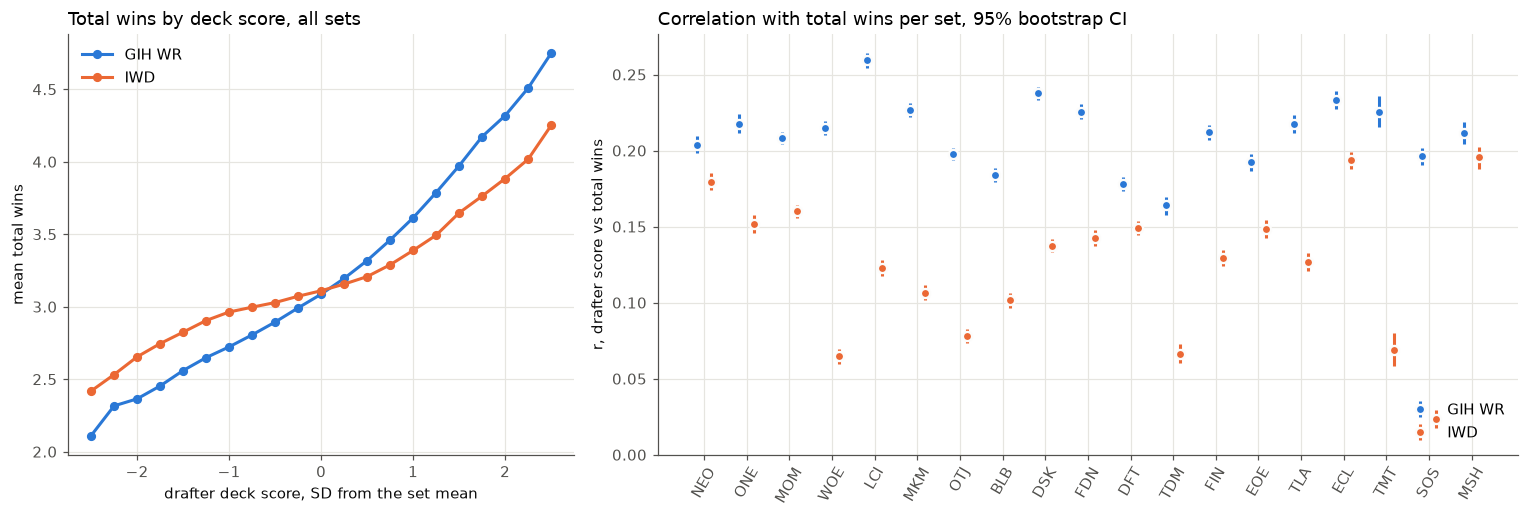

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axes[0]
for m, label in METRICS.items():
    b = (drafts.with_columns(((pl.col(f"z_{m}") * 4).round() / 4).clip(-2.5, 2.5).alias("bin"))
         .group_by("bin").agg(pl.col("wins").mean(), pl.len()).filter(pl.col("len") >= 1000).sort("bin"))
    ax.plot(b["bin"], b["wins"], "o-", color=M_COLOR[m], ms=5, label=label)
ax.set_xlabel("drafter deck score, SD from the set mean")
ax.set_ylabel("mean total wins")
ax.set_title("Total wins by deck score, all sets", loc="left"); ax.legend()

ax = axes[1]
x = np.arange(len(SETS))
for dx, (m, label) in zip((-0.17, 0.17), METRICS.items()):
    r_ = wins_r[f"r wins {m}"].to_numpy()
    ax.errorbar(x + dx, r_, yerr=[r_ - wins_r[f"lo {m}"].to_numpy(), wins_r[f"hi {m}"].to_numpy() - r_], fmt="o",
                color=M_COLOR[m], ecolor=M_COLOR[m], elinewidth=2, capsize=0, ms=6, mec=SURFACE, mew=1.5, label=label)
ax.set_xticks(x, SETS, rotation=60)
ax.set_ylim(0, None)
ax.set_ylabel("r, drafter score vs total wins")
ax.set_title("Correlation with total wins per set, 95% bootstrap CI", loc="left"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 3. Bombs

Section 2 shows that the card ratings (shrunk normalized GIH WR or IWD, Premier Draft) predict games won. This section looks at the distribution of those ratings within each set and
calls a card a **bomb** if it's an upper outlier. Everything is done separately for each metric, so a card can be a
bomb under one and not the other.

**Definition.** Within each set, a card is a bomb if its rating is above the **Tukey upper fence**, Q3 + 1.5 × IQR. That's
the standard boxplot outlier rule. It uses the set's own middle 50% of cards as the yardstick, so a weak set's
filler doesn't stretch it. It's easiest to read on a robust z scale, z = (rating − median) / (IQR / 1.349). On that scale, IQR / 1.349 is the
SD a normal distribution with the same IQR would have, and the fence sits at **z = 2.70**. If ratings were normal, only 0.35% of
cards (about one per set) would clear it, so any excess over that is a fat right tail.

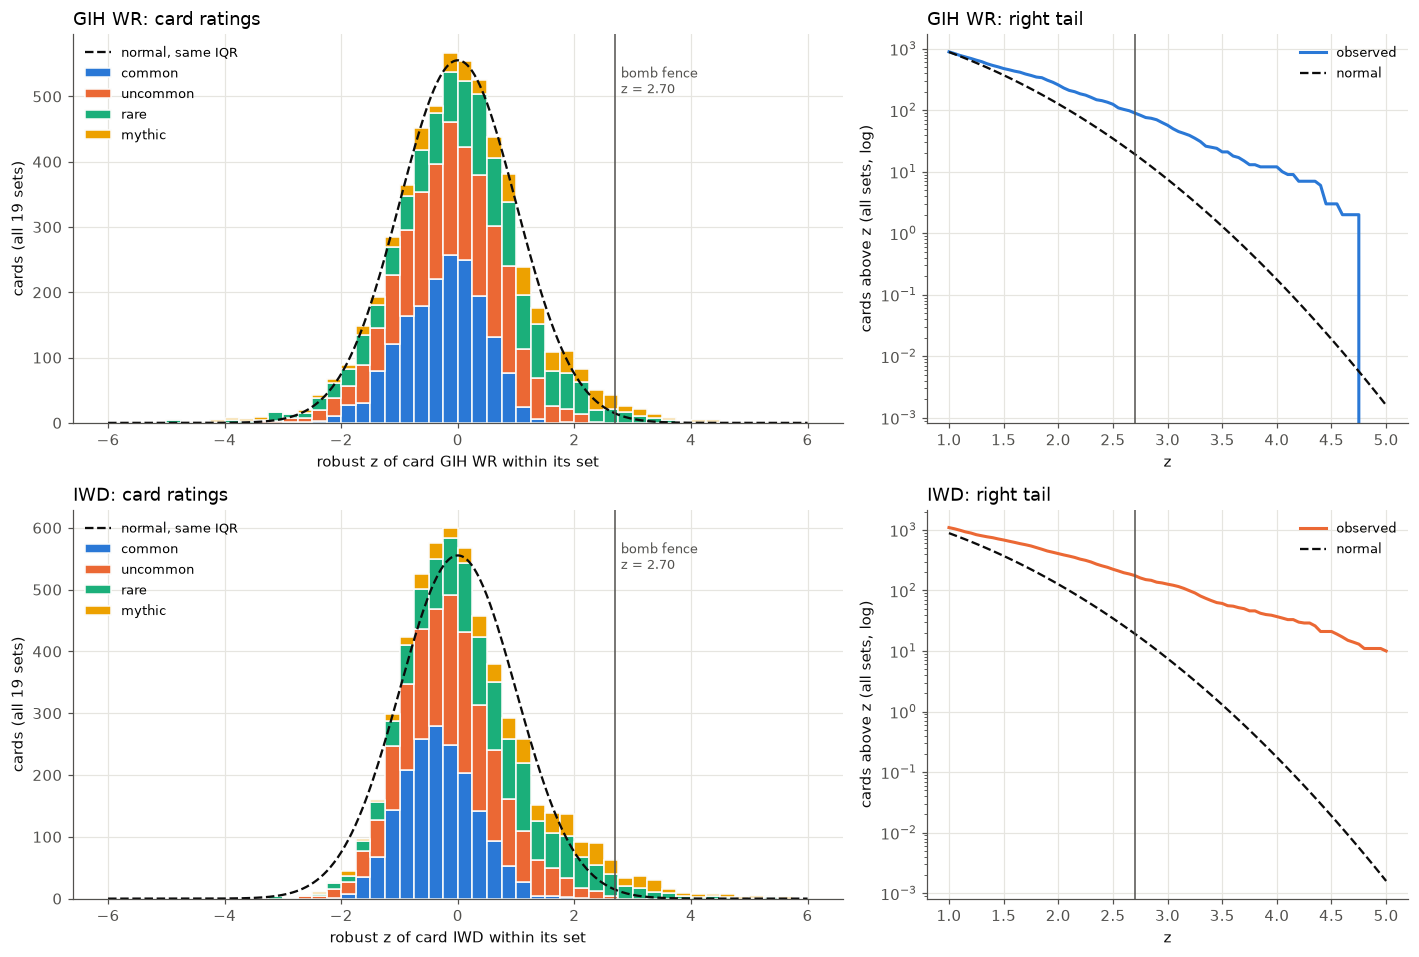

GIH WR: cards: 5568, above the fence: 90 (normal would give 19); below the lower fence: 69
  z > 2.00: 13.6 cards per set (normal: 6.7)
  z > 2.50: 6.6 cards per set (normal: 1.8)
  z > 2.70: 4.7 cards per set (normal: 1.0)
  z > 3.00: 3.0 cards per set (normal: 0.4)
  z > 3.50: 1.1 cards per set (normal: 0.1)
IWD: cards: 5568, above the fence: 176 (normal would give 19); below the lower fence: 14
  z > 2.00: 21.4 cards per set (normal: 6.7)
  z > 2.50: 11.8 cards per set (normal: 1.8)
  z > 2.70: 9.3 cards per set (normal: 1.0)
  z > 3.00: 6.7 cards per set (normal: 0.4)
  z > 3.50: 3.2 cards per set (normal: 0.1)


In [11]:
FENCE_Z = 0.6745 + 1.5 * 1.349   # Q3 + 1.5 IQR, in units of IQR / 1.349
from scipy.stats import norm

r = pl.concat([
    cards.filter(pl.col("event") == "PremierDraft").with_columns(pl.lit(m).alias("metric"), pl.col(col).alias("rating"))
    for m, col in RATING.items()])
r = (r.with_columns(pl.col("rating").median().over("metric", "set").alias("med"),
                    ((pl.col("rating").quantile(0.75) - pl.col("rating").quantile(0.25)) / 1.349).over("metric", "set").alias("sig"))
     .with_columns(((pl.col("rating") - pl.col("med")) / pl.col("sig")).alias("z"))
     .with_columns((pl.col("z") > FENCE_Z).alias("bomb")))

RARITIES = ["common", "uncommon", "rare", "mythic"]
R_COLOR = dict(zip(RARITIES, [BLUE, ORANGE, AQUA, YELLOW]))
bins = np.arange(-6, 6.01, 0.25)
xs = np.linspace(-6, 6, 400)
zz = np.linspace(1, 5, 81)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.8), gridspec_kw={"width_ratios": [1.6, 1]})
for row, (m, label) in zip(axes, METRICS.items()):
    rm = r.filter(pl.col("metric") == m)
    z = rm["z"].to_numpy()
    ax = row[0]
    bottom = np.zeros(len(bins) - 1)
    for k in RARITIES:
        h, _ = np.histogram(z[rm["rarity"].to_numpy() == k], bins)
        ax.bar(bins[:-1], h, width=0.25, align="edge", bottom=bottom, color=R_COLOR[k], edgecolor=SURFACE, lw=1, label=k)
        bottom += h
    ax.plot(xs, norm.pdf(xs) * len(z) * 0.25, color=INK, lw=1.5, ls="--", label="normal, same IQR")
    ax.axvline(FENCE_Z, color=MUTED, lw=1)
    ax.text(FENCE_Z + 0.1, ax.get_ylim()[1] * 0.92, "bomb fence\nz = 2.70", fontsize=8.5, color=MUTED, va="top")
    ax.set_xlabel(f"robust z of card {label} within its set"); ax.set_ylabel("cards (all 19 sets)")
    ax.set_title(f"{label}: card ratings", loc="left"); ax.legend(fontsize=8.5)

    ax = row[1]   # the right tail on a log scale: observed cards above z vs a normal
    ax.semilogy(zz, [(z > t).sum() for t in zz], color=M_COLOR[m], label="observed")
    ax.semilogy(zz, norm.sf(zz) * len(z), color=INK, ls="--", lw=1.5, label="normal")
    ax.axvline(FENCE_Z, color=MUTED, lw=1)
    ax.set_xlabel("z"); ax.set_ylabel("cards above z (all sets, log)")
    ax.set_title(f"{label}: right tail", loc="left"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

for m, label in METRICS.items():
    z = r.filter(pl.col("metric") == m)["z"].to_numpy()
    print(f"{label}: cards: {len(z)}, above the fence: {(z > FENCE_Z).sum()} (normal would give {norm.sf(FENCE_Z) * len(z):.0f}); "
          f"below the lower fence: {(z < -FENCE_Z).sum()}")
    for t in [2.0, 2.5, FENCE_Z, 3.0, 3.5]:
        print(f"  z > {t:.2f}: {(z > t).sum() / len(SETS):.1f} cards per set (normal: {norm.sf(t) * len(z) / len(SETS):.1f})")

### 3a. The bombs in each set

`fence` is the bomb cutoff in pp above the set's average win rate. `bombs` is how many cards clear it, with their
rarity mix. The cards are listed with their rating in pp. One table per metric, then the overlap between the two bomb lists.

In [12]:
bombs = r.filter(pl.col("bomb"))
fences = r.group_by("metric", "set").agg((pl.col("med") + FENCE_Z * pl.col("sig")).first().alias("fence"),
                                         pl.len().alias("cards"))
bomb_tbl = {}
for m, label in METRICS.items():
    rows = []
    for s in SETS:
        b = bombs.filter((pl.col("metric") == m) & (pl.col("set") == s)).sort("rating", descending=True)
        f = fences.filter((pl.col("metric") == m) & (pl.col("set") == s))
        rows.append({"set": s, "cards": f["cards"][0], "fence": f["fence"][0], "bombs": b.height,
                     **{k[0].upper(): (b["rarity"] == k).sum() for k in RARITIES},
                     "cards (pp)": ", ".join(f"{n} {v:+.1f}" for n, v in zip(b["name"], b["rating"]))})
    bomb_tbl[m] = pl.DataFrame(rows)
    print(f"\n{label}")
    with pl.Config(fmt_str_lengths=400, tbl_width_chars=600):
        display(bomb_tbl[m])
    print("bombs by rarity, all sets:", dict(bombs.filter(pl.col("metric") == m)["rarity"].value_counts().iter_rows()))

both = {m: set(bombs.filter(pl.col("metric") == m).select(pl.concat_str("set", "name", separator="|"))["set"]) for m in METRICS}
print(f"\nbombs under both: {len(both['gih'] & both['iwd'])}; GIH WR only: {len(both['gih'] - both['iwd'])}; "
      f"IWD only: {len(both['iwd'] - both['gih'])}")
for m, other in [("gih", "iwd"), ("iwd", "gih")]:
    print(f"  {METRICS[m]} only: " + ", ".join(sorted(both[m] - both[other])).replace("|", " "))


GIH WR


set,cards,fence,bombs,C,U,R,M,cards (pp)
str,i64,f64,i64,i64,i64,i64,i64,str
"""NEO""",280,9.63,5,0,0,3,2,"""Jugan Defends the Temple +12.7, Fable of the Mirror-Breaker +11.6, The Wandering Emperor +11.2, Inventive Iteration +10.4, Farewell +10.4"""
"""ONE""",260,10.57,2,0,0,1,1,"""Nissa, Ascended Animist +12.1, Migloz, Maze Crusher +12.0"""
"""MOM""",341,8.80,7,0,0,5,2,"""Elesh Norn, Grand Cenobite +12.5, Sunfall +12.2, Chrome Host Seedshark +10.1, Boon-Bringer Valkyrie +9.5, Zephyr Singer +9.0, Sheoldred +9.0, Glissa, Herald of Predation +8.8"""
"""WOE""",307,9.24,2,0,0,1,1,"""Gruff Triplets +13.7, Virtue of Persistence +11.1"""
"""LCI""",285,8.92,10,0,0,7,3,"""Bonehoard Dracosaur +14.9, Aclazotz, Deepest Betrayal +13.5, Palani's Hatcher +12.0, Kitesail Larcenist +10.2, Unstable Glyphbridge +9.9, Magmatic Galleon +9.9, Sanguine Evangelist +9.8, Huatli, Poet of Unity +9.7, Breeches, Eager Pillager +9.5, Sentinel of the Nameless City +9.1"""
"""MKM""",303,8.56,3,0,0,1,2,"""Aurelia's Vindicator +13.3, Izoni, Center of the Web +10.1, Agrus Kos, Spirit of Justice +8.7"""
"""OTJ""",368,8.87,8,0,0,2,6,"""Bonny Pall, Clearcutter +12.1, Railway Brawler +11.0, Overwhelming Forces +10.5, Oko, Thief of Crowns +10.0, Vaultborn Tyrant +9.9, Rakdos, the Muscle +9.7, Roxanne, Starfall Savant +9.5, Bristly Bill, Spine Sower +9.3"""
"""BLB""",268,9.13,6,0,0,4,2,"""Season of Loss +11.0, Sword of Fire and Ice +10.1, Dreamdew Entrancer +10.0, Valley Questcaller +9.7, Mabel, Heir to Cragflame +9.3, Fecund Greenshell +9.3"""
"""DSK""",275,8.47,8,0,0,4,4,"""Overlord of the Mistmoors +13.6, Valgavoth's Onslaught +11.4, Unholy Annex // Ritual Chamber +10.2, The Swarmweaver +9.9, Ghostly Dancers +9.8, Overlord of the Boilerbilges +9.5, Overlord of the Floodpits +8.6, Tyvar, the Pummeler +8.5"""


bombs by rarity, all sets: {'mythic': 45, 'rare': 45}

IWD


set,cards,fence,bombs,C,U,R,M,cards (pp)
str,i64,f64,i64,i64,i64,i64,i64,str
"""NEO""",280,10.95,12,0,0,6,6,"""The Kami War +17.7, Jugan Defends the Temple +15.7, Fable of the Mirror-Breaker +15.2, The Wandering Emperor +14.7, Kairi, the Swirling Sky +13.0, Farewell +12.8, Inventive Iteration +12.7, Ao, the Dawn Sky +11.9, Invoke the Ancients +11.8, Tatsunari, Toad Rider +11.5, Tameshi, Reality Architect +11.4, Junji, the Midnight Sky +11.0"""
"""ONE""",260,9.83,7,0,0,4,3,"""Atraxa, Grand Unifier +17.9, Nissa, Ascended Animist +14.8, Sheoldred, the Apocalypse +14.1, Migloz, Maze Crusher +12.9, Archfiend of the Dross +12.2, The Eternal Wanderer +11.1, White Sun's Twilight +9.9"""
"""MOM""",341,9.03,15,0,0,8,7,"""Elesh Norn, Grand Cenobite +14.7, Sunfall +14.1, Chrome Host Seedshark +11.6, Glissa, Herald of Predation +11.5, Chandra, Hope's Beacon +11.4, Breach the Multiverse +10.8, Borborygmos and Fblthp +10.8, Boon-Bringer Valkyrie +10.6, Sheoldred +10.4, Vorinclex +10.4, Atraxa, Praetors' Voice +10.3, Etali, Primal Conqueror +10.1, Invasion of New Phyrexia +9.7, Hidetsugu and Kairi +9.5, Kogla and Yidaro…"
"""WOE""",307,9.26,9,0,0,7,2,"""Gruff Triplets +16.9, Virtue of Persistence +13.1, Horned Loch-Whale +12.3, The Goose Mother +10.9, Talion's Messenger +10.6, Sleep-Cursed Faerie +10.5, Faunsbane Troll +9.7, Virtue of Loyalty +9.6, Twining Twins +9.4"""
"""LCI""",285,10.33,13,0,0,8,5,"""Aclazotz, Deepest Betrayal +17.1, Bonehoard Dracosaur +16.4, Palani's Hatcher +13.6, Ojer Kaslem, Deepest Growth +12.3, Huatli, Poet of Unity +11.9, Preacher of the Schism +11.0, Unstable Glyphbridge +11.0, Sentinel of the Nameless City +10.9, Magmatic Galleon +10.7, Quintorius Kand +10.5, Throne of the Grim Captain +10.4, Kitesail Larcenist +10.4, Pugnacious Hammerskull +10.4"""
"""MKM""",303,8.16,16,0,0,8,8,"""Izoni, Center of the Web +14.5, Aurelia's Vindicator +13.8, Vein Ripper +12.5, Ezrim, Agency Chief +11.3, Tolsimir, Midnight's Light +10.9, Teysa, Opulent Oligarch +10.6, Hide in Plain Sight +10.2, Vannifar, Evolved Enigma +10.1, Cryptic Coat +10.0, Rakdos, Patron of Chaos +10.0, Crashing Footfalls +9.9, Doppelgang +9.4, Agrus Kos, Spirit of Justice +9.4, Kaya, Spirits' Justice +9.2, Ill-Timed Exp…"
"""OTJ""",368,10.68,8,0,0,3,5,"""Bonny Pall, Clearcutter +15.9, Rakdos, the Muscle +13.5, Oko, Thief of Crowns +12.7, Overwhelming Forces +12.7, Railway Brawler +12.4, Cruel Ultimatum +12.3, Fractured Identity +11.6, Roxanne, Starfall Savant +11.0"""
"""BLB""",268,11.96,3,0,0,2,1,"""Dreamdew Entrancer +13.9, Season of Loss +13.2, Mabel, Heir to Cragflame +12.5"""
"""DSK""",275,10.38,7,0,0,6,1,"""Overlord of the Mistmoors +15.9, Unholy Annex // Ritual Chamber +14.7, Valgavoth's Onslaught +14.5, The Swarmweaver +13.5, Ghostly Dancers +11.9, Roaring Furnace // Steaming Sauna +10.6, Zimone, All-Questioning +10.4"""


bombs by rarity, all sets: {'rare': 86, 'mythic': 90}

bombs under both: 77; GIH WR only: 13; IWD only: 99
  GIH WR only: BLB Fecund Greenshell, BLB Sword of Fire and Ice, BLB Valley Questcaller, DSK Overlord of the Boilerbilges, DSK Overlord of the Floodpits, DSK Tyvar, the Pummeler, LCI Breeches, Eager Pillager, LCI Sanguine Evangelist, MOM Zephyr Singer, OTJ Bristly Bill, Spine Sower, OTJ Vaultborn Tyrant, SOS Antiquities on the Loose, TMT Umezawa's Jitte
  IWD only: DFT Captain Howler, Sea Scourge, DFT Draconautics Engineer, DFT Howlsquad Heavy, DFT March of the World Ooze, DFT Perilous Snare, DFT Pyrewood Gearhulk, DFT Riptide Gearhulk, DSK Roaring Furnace // Steaming Sauna, DSK Zimone, All-Questioning, ECL Chronicle of Victory, ECL Curious Colossus, ECL Kinbinding, ECL Soul Immolation, ECL Spinerock Tyrant, ECL Sunderflock, ECL Trystan's Command, EOE Cosmogrand Zenith, EOE Genemorph Imago, EOE Nova Hellkite, FDN Alesha, Who Laughs at Fate, FDN Bloodthirsty Conqueror, FDN Liliana,

### 3b. How often do you see one?

From the 17Lands draft logs (no pick data for NEO or ONE):

* **Opened packs.** The pack at pick 1 of each round is a whole freshly opened 14-card pack. `P(pack)` is the share of
  those packs with at least one bomb. `per pod` is the expected number of bombs opened at an 8-player table (24 packs).
* **Final pool.** Every card the drafter picked (42). `P(pool ≥1)` and `P(pool ≥2)` are the share of complete drafts
  with at least one or two bombs. This is what 17Lands users actually end up with, and they're above-average drafters
  who take bombs when they see them.

Computed separately for each metric's bomb list (`bomb_frequency_{gih,iwd}.csv`).

In [13]:
def bomb_freq(s, m):
    lf = pl.scan_parquet(ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet")
    names = set(bombs.filter((pl.col("metric") == m) & (pl.col("set") == s))["name"])
    cols = [f"pack_card_{n}" for n in names if f"pack_card_{n}" in lf.collect_schema().names()]
    n = lf.group_by("draft_id").len()
    full = n.filter(pl.col("len") == pl.col("len").mode().first()).select("draft_id")
    packs = (lf.filter(pl.col("pick_number") == 0)
             .select(pl.sum_horizontal(cols).alias("b") if cols else pl.lit(0).alias("b")).collect()["b"].to_numpy())
    pool = (lf.join(full, on="draft_id").group_by("draft_id").agg(pl.col("pick").is_in(list(names)).sum().alias("b"))
            .collect()["b"].to_numpy())
    return {"set": s, "bombs": len(names), "P(pack)": (packs > 0).mean(), "per pod": packs.mean() * 24,
            "P(pool ≥1)": (pool >= 1).mean(), "P(pool ≥2)": (pool >= 2).mean(), "mean in pool": pool.mean(),
            "drafts": len(pool)}

DRAFT_SETS = [s for s in SETS if (ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").exists()]
freq = {}
for m, label in METRICS.items():
    freq[m] = pl.DataFrame([bomb_freq(s, m) for s in DRAFT_SETS])
    freq[m].write_csv(OUT / f"bomb_frequency_{m}.csv")
    print(f"\n{label}")
    display(freq[m])
    print("median over sets:", {k: round(float(freq[m][k].median()), 3) for k in freq[m].columns[1:-1]})


GIH WR


set,bombs,P(pack),per pod,P(pool ≥1),P(pool ≥2),mean in pool,drafts
str,i64,f64,f64,f64,f64,f64,i64
"""MOM""",7,0.08,2.01,0.25,0.03,0.27,205437
"""WOE""",2,0.02,0.52,0.07,0.00,0.07,165792
"""LCI""",10,0.11,2.70,0.31,0.05,0.36,134970
"""MKM""",3,0.04,0.84,0.11,0.01,0.12,157553
"""OTJ""",8,0.07,1.77,0.22,0.02,0.24,195312
"""BLB""",6,0.08,1.96,0.23,0.03,0.26,154585
"""DSK""",8,0.11,2.58,0.30,0.04,0.35,167672
"""FDN""",0,0.00,0.00,0.00,0.00,0.00,130935
"""DFT""",6,0.07,1.61,0.19,0.02,0.22,141166


median over sets: {'bombs': 3.0, 'P(pack)': 0.045, 'per pod': 1.081, 'P(pool ≥1)': 0.154, 'P(pool ≥2)': 0.01, 'mean in pool': 0.164}



IWD


set,bombs,P(pack),per pod,P(pool ≥1),P(pool ≥2),mean in pool,drafts
str,i64,f64,f64,f64,f64,f64,i64
"""MOM""",15,0.16,3.83,0.41,0.09,0.51,205437
"""WOE""",9,0.11,2.76,0.30,0.06,0.37,165792
"""LCI""",13,0.14,3.34,0.36,0.06,0.43,134970
"""MKM""",16,0.20,4.92,0.49,0.15,0.67,157553
"""OTJ""",8,0.07,1.76,0.22,0.02,0.25,195312
"""BLB""",3,0.04,1.07,0.13,0.01,0.14,154585
"""DSK""",7,0.11,2.79,0.33,0.06,0.39,167672
"""FDN""",4,0.05,1.12,0.14,0.01,0.15,130935
"""DFT""",13,0.17,4.07,0.41,0.09,0.52,141166


median over sets: {'bombs': 9.0, 'P(pack)': 0.115, 'per pod': 2.788, 'P(pool ≥1)': 0.304, 'P(pool ≥2)': 0.055, 'mean in pool': 0.368}


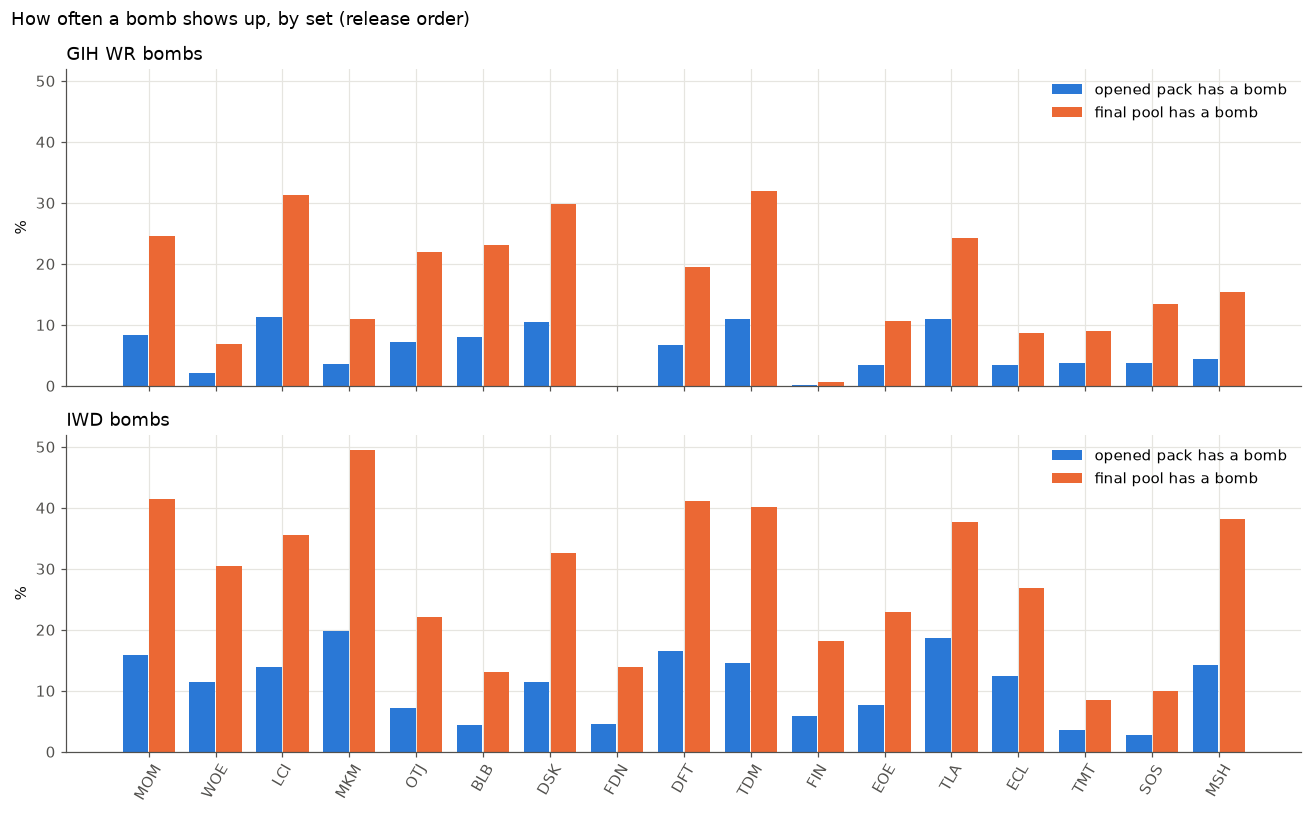

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (m, label) in zip(axes, METRICS.items()):
    f = freq[m]
    x = np.arange(f.height)
    ax.bar(x - 0.2, f["P(pack)"] * 100, width=0.38, color=BLUE, label="opened pack has a bomb")
    ax.bar(x + 0.2, f["P(pool ≥1)"] * 100, width=0.38, color=ORANGE, label="final pool has a bomb")
    ax.set_ylabel("%"); ax.set_title(f"{label} bombs", loc="left"); ax.legend()
axes[1].set_xticks(x, freq["gih"]["set"], rotation=60)
fig.suptitle("How often a bomb shows up, by set (release order)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()